In [97]:
import os
import zipfile
import  numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import tensorflow as tf

In [98]:
!pip install tensorflow

In [99]:

from google.colab import files

uploaded = files.upload()


Saving kaggle.json to kaggle (3).json


In [100]:
import os

print(os.listdir("/content"))

['.config', 'kaggle (3).json', 'solar_dataset_new', 'kaggle_download', 'kaggle (2).json', 'intelligent_review_queue.csv', 'ml_benchmark_results.csv', 'kaggle.json', 'intelligent_review_results.csv', 'archive (5).zip', 'best_mobilenetv2.keras', 'mobilenetv2_current.keras', 'best_solar_cnn.keras', 'kaggle (1).json', 'sample_data']


In [101]:

import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)

shutil.copy(
    "/content/kaggle (1).json",
    "/root/.kaggle/kaggle.json"
)

os.chmod("/root/.kaggle/kaggle.json", 0o600)

!pip -q install kaggle

print("Kaggle setup completed!")


Kaggle setup completed!


In [102]:

import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)

shutil.copy(
    "/content/kaggle (1).json",
    "/root/.kaggle/kaggle.json"
)

os.chmod("/root/.kaggle/kaggle.json", 0o600)

!pip -q install kaggle


In [104]:

import os

os.makedirs("/content/kaggle_download", exist_ok=True)

!kaggle datasets download \
    -d pythonafroz/solar-panel-images \
    -p /content/kaggle_download


Dataset URL: https://www.kaggle.com/datasets/pythonafroz/solar-panel-images
License(s): unknown
solar-panel-images.zip: Skipping, found more recently modified local copy (use --force to force download)


In [105]:

import os
import glob
import zipfile

extract_path = "/content/solar_dataset_new"
os.makedirs(extract_path, exist_ok=True)

zip_files = glob.glob("/content/kaggle_download/*.zip")

if not zip_files:
    print("No ZIP file downloaded. Check the download output.")
else:
    for zip_path in zip_files:
        print("Checking:", zip_path)
        print("Size:", os.path.getsize(zip_path), "bytes")

        if zipfile.is_zipfile(zip_path):
            with zipfile.ZipFile(zip_path, "r") as z:
                bad_file = z.testzip()

                if bad_file is None:
                    z.extractall(extract_path)
                    print("Extracted successfully!")
                else:
                    print("Corrupted file inside ZIP:", bad_file)
        else:
            print("Invalid ZIP. Download may be incomplete.")

    print("Dataset folders:", os.listdir(extract_path))


Checking: /content/kaggle_download/solar-panel-images.zip
Size: 319746451 bytes
Extracted successfully!
Dataset folders: ['Faulty_solar_panel']


# **Read & load el data**

In [106]:
import os
print(os.listdir("/content"))

['.config', 'kaggle (3).json', 'solar_dataset_new', 'kaggle_download', 'kaggle (2).json', 'intelligent_review_queue.csv', 'ml_benchmark_results.csv', 'kaggle.json', 'intelligent_review_results.csv', 'archive (5).zip', 'best_mobilenetv2.keras', 'mobilenetv2_current.keras', 'best_solar_cnn.keras', 'kaggle (1).json', 'sample_data']


In [107]:
import zipfile
zip_path = "/content/archive (13).zip"
print(zipfile.is_zipfile(zip_path))

False


In [108]:
import os
for root, dirs, files in os.walk("/content/solar_dataset"):
    level = root.replace("/content/solar_dataset", "").count(os.sep)
    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")
    sub_indent = " " * 4 * (level + 1)

    for f in files[:2]:
        print(f"{sub_indent}{f}")

# **EDA**

In [109]:
for folder in sorted(os.listdir(dataset_path)):
  folder_path = os.path.join(dataset_path, folder)
  if os.path.isdir(folder_path):
    print(folder)

Bird-drop
Clean
Dusty
Electrical-damage
Physical-Damage
Snow-Covered


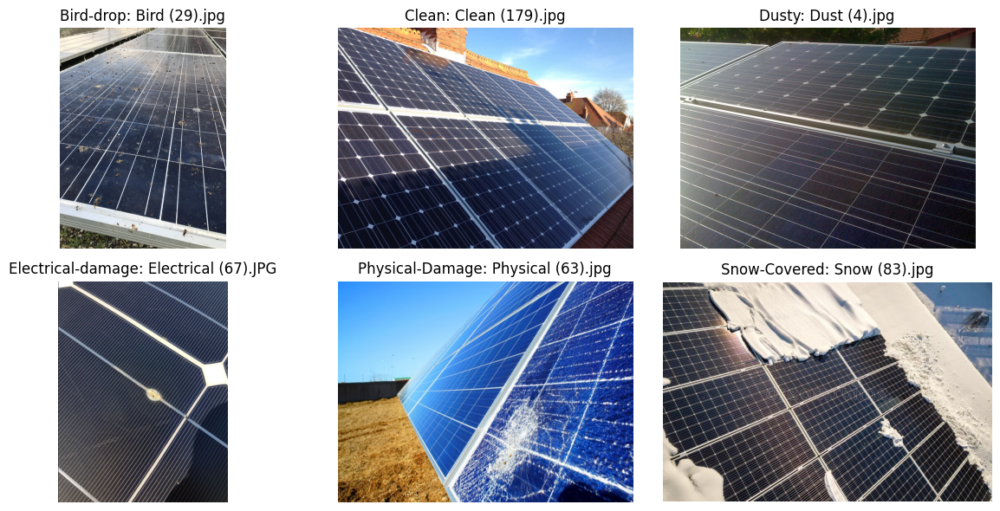

In [110]:
import random
import matplotlib.pyplot as plt

classes = sorted([
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
])

plt.figure(figsize=(12, 6))
for i , class_name in enumerate(classes, 1):
  class_path = os.path.join(dataset_path, class_name)
  images = [
      f for f in os.listdir(class_path)
  if f.lower().endswith(('.jpg', '.jpeg', '.png'))
  ]

  if len(images) == 0:
    print(f"No images found in {class_path}")
    continue

  random_image = random.choice(images)
  image_path = os.path.join(class_path, random_image)

  with Image.open(image_path) as image:
    plt.subplot(2, 3, i)
    plt.imshow(image)
    plt.title(f"{class_name}: {random_image}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [111]:
valid_extentions = ('.jpg', '.jpeg', '.png')
total_images = 0
bad_images = []

for class_name in classes:
  class_path = os.path.join(dataset_path, class_name)
  for file in os.listdir(class_path):
    if file.lower().endswith(valid_extentions):
      image_path = os.path.join(class_path, file)

      try:
        with Image.open(image_path) as img:
          img.verify()
          total_images += 1
      except Exception:
        bad_images.append(image_path)

print("Total valid images:", total_images)
print("Total bad images:", len(bad_images))

Total valid images: 869
Total bad images: 0


In [114]:
import os
from PIL import Image
from collections import Counter

dataset_path = "/content/solar_dataset/PRoject"
classes = sorted([
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
])

image_sizes = Counter()

for class_name in classes:
  class_path = os.path.join(dataset_path, class_name)
  for file in os.listdir(class_path):
    if file.lower().endswith((".jpg", ".jpeg", ".png")):
      image_path = os.path.join(class_path, file)
      with Image.open(image_path) as img:
        image_sizes[img.size] += 1

print("Different image sizes:", len(image_sizes))
print("Most common image sizes:")
for size, count in image_sizes.most_common(10):
  print(size, ":", count)

Different image sizes: 446
Most common image sizes:
(720, 960) : 58
(2048, 1152) : 23
(1536, 2048) : 22
(474, 355) : 22
(2048, 1536) : 22
(800, 600) : 18
(960, 720) : 18
(474, 632) : 15
(1024, 768) : 12
(800, 533) : 10


In [115]:
class_counts= {}
for class_name in classes:
  class_path = os.path.join(dataset_path, class_name)

  image_files = [
      f for f in os.listdir(class_path)
      if f.lower().endswith((".jpg", ".jpeg", ".png"))
  ]
  class_counts[class_name] = len(image_files)

print("Class counts:")
for class_name, count in class_counts.items():
  print(class_name, ":", count)
print("Total images:", sum(class_counts.values()))

Class counts:
Bird-drop : 191
Clean : 193
Dusty : 190
Electrical-damage : 103
Physical-Damage : 69
Snow-Covered : 123
Total images: 869


In [116]:
image_path=[]
labels=[]

valid_extentions= (".jpg", ".jpeg",".png")

for class_name in classes:
  class_path =os.path.join(dataset_path, class_name)
  for file in os.listdir(class_path):
    if file.lower().endswith(valid_extentions):
      image_path.append(os.path.join(class_path, file))
      labels.append(class_name)
df = pd.DataFrame({"image_path": image_path, "labels": labels})

print("Total images:", len(df))
print("\nImages per class:")
print(df["labels"].value_counts())

Total images: 869

Images per class:
labels
Clean                193
Bird-drop            191
Dusty                190
Snow-Covered         123
Electrical-damage    103
Physical-Damage       69
Name: count, dtype: int64


In [117]:
print(df.shape)
print(df.head())
print(df["labels"].value_counts())

(869, 2)
                                          image_path     labels
0  /content/solar_dataset_new/Faulty_solar_panel/...  Bird-drop
1  /content/solar_dataset_new/Faulty_solar_panel/...  Bird-drop
2  /content/solar_dataset_new/Faulty_solar_panel/...  Bird-drop
3  /content/solar_dataset_new/Faulty_solar_panel/...  Bird-drop
4  /content/solar_dataset_new/Faulty_solar_panel/...  Bird-drop
labels
Clean                193
Bird-drop            191
Dusty                190
Snow-Covered         123
Electrical-damage    103
Physical-Damage       69
Name: count, dtype: int64


# **Split el data**

In [118]:
from sklearn.model_selection import train_test_split
train_df ,temp_df = train_test_split(
    df,
    test_size=0.4,
    random_state=42,
    stratify=df["labels"]
)

val_df , test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=42,
    stratify=temp_df["labels"]
)

print("Training_Images:", len(train_df))
print("Validation_Images:", len(val_df))
print("Test_Images:", len(test_df))

Training_Images: 521
Validation_Images: 174
Test_Images: 174


# **Check el duplicates**

In [119]:
import hashlib
df['hash']= df['image_path'].apply(lambda p: hashlib.md5(open(p , "rb").read()).hexdigest())
print("Total images:", len(df))
print("Exact duplicates:", df["hash"].duplicated().sum())

Total images: 869
Exact duplicates: 91


In [120]:
duplicates = df[df["hash"].duplicated(keep=False)].copy()

print("Images involved in duplicates:", len(duplicates))
print("\nDuplicates per class:")
print(duplicates.groupby("labels").size())

print("\nClasses for each duplicated image:")
print(
    duplicates.groupby("hash")["labels"]
    .nunique()
    .value_counts()
)

Images involved in duplicates: 165

Duplicates per class:
labels
Bird-drop            85
Clean                13
Dusty                14
Electrical-damage    24
Physical-Damage      11
Snow-Covered         18
dtype: int64

Classes for each duplicated image:
labels
1    72
2     2
Name: count, dtype: int64


In [121]:
cross_class = (
    duplicates.groupby("hash")
    .filter(lambda g: g["labels"].nunique() > 1)
    .sort_values("hash")
)

print(cross_class[["image_path", "labels", "hash"]].to_string(index=False))

                                                                     image_path          labels                             hash
         /content/solar_dataset_new/Faulty_solar_panel/Bird-drop/Bird (193).jpg       Bird-drop a5c5841cf608a86e08b63c02b9eab2a6
             /content/solar_dataset_new/Faulty_solar_panel/Dusty/Dust (187).jpg           Dusty a5c5841cf608a86e08b63c02b9eab2a6
          /content/solar_dataset_new/Faulty_solar_panel/Bird-drop/Bird (22).jpg       Bird-drop b932e847d063bac3e4943fc677a19c59
         /content/solar_dataset_new/Faulty_solar_panel/Bird-drop/Bird (184).jpg       Bird-drop b932e847d063bac3e4943fc677a19c59
         /content/solar_dataset_new/Faulty_solar_panel/Bird-drop/Bird (176).jpg       Bird-drop b932e847d063bac3e4943fc677a19c59
          /content/solar_dataset_new/Faulty_solar_panel/Bird-drop/Bird (46).jpg       Bird-drop b932e847d063bac3e4943fc677a19c59
          /content/solar_dataset_new/Faulty_solar_panel/Bird-drop/Bird (57).jpg       Bird-drop b

In [122]:
path_to_hash = df.drop_duplicates("image_path").set_index("image_path")["hash"]

train_hashes = set(train_df["image_path"].map(path_to_hash).dropna())
val_hashes = set(val_df["image_path"].map(path_to_hash).dropna())
test_hashes = set(test_df["image_path"].map(path_to_hash).dropna())

print("Train-Validation overlap:", len(train_hashes & val_hashes))
print("Train-Test overlap:", len(train_hashes & test_hashes))
print("Validation-Test overlap:", len(val_hashes & test_hashes))

Train-Validation overlap: 21
Train-Test overlap: 26
Validation-Test overlap: 11


In [123]:
# 1. Create a separate working copy
df_clean = df.copy()

# 2. Count exact duplicate images
duplicate_count = df_clean["hash"].duplicated().sum()

# 3. Find images that have conflicting labels
labels_per_hash = df_clean.groupby("hash")["labels"].nunique()
conflicting_hashes = labels_per_hash[labels_per_hash > 1].index

print("Original dataframe rows:", len(df))
print("Exact duplicate rows:", duplicate_count)
print("Images with conflicting labels:", len(conflicting_hashes))

print("\nConflicting labels:")
print(
    df_clean[df_clean["hash"].isin(conflicting_hashes)]
    .groupby("hash")["labels"]
    .unique()
    .head(20)
)

Original dataframe rows: 869
Exact duplicate rows: 91
Images with conflicting labels: 2

Conflicting labels:
hash
a5c5841cf608a86e08b63c02b9eab2a6              [Bird-drop, Dusty]
b932e847d063bac3e4943fc677a19c59    [Bird-drop, Physical-Damage]
Name: labels, dtype: object


# **handeling el duplicates**

# **New split after removing el duplicates**

In [124]:
from sklearn.model_selection import train_test_split

# Keep the original df and old splits unchanged
df_clean = df.drop_duplicates(subset="hash").copy()

# Exclude images whose identical copies have conflicting labels
df_clean = df_clean[ ~df_clean["hash"].isin(conflicting_hashes) ].copy()

# New splits with separate names
train_df_clean, temp_df_clean = train_test_split( df_clean, test_size=0.4, random_state=42, stratify=df_clean["labels"] )
val_df_clean, test_df_clean = train_test_split( temp_df_clean, test_size=0.5, random_state=42, stratify=temp_df_clean["labels"] )

# Verify no exact-hash overlap
for name, a, b in [ ("Train-Val", train_df_clean, val_df_clean), ("Train-Test", train_df_clean, test_df_clean), ("Val-Test", val_df_clean, test_df_clean) ]:
    overlap = set(a["hash"]) & set(b["hash"])
    print(f"{name} overlap: {len(overlap)}")

print("\nNew split sizes:")
print("Train:", len(train_df_clean))
print("Validation:", len(val_df_clean))
print("Test:", len(test_df_clean))
print("\nClass counts after cleaning:")
print(df_clean["labels"].value_counts())

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0

New split sizes:
Train: 465
Validation: 155
Test: 156

Class counts after cleaning:
labels
Clean                186
Dusty                182
Bird-drop            141
Snow-Covered         113
Electrical-damage     91
Physical-Damage       63
Name: count, dtype: int64


In [125]:
print("Train labels:", train_df_clean["labels"].unique())
print("Val labels:", val_df_clean["labels"].unique())
print("Test labels:", test_df_clean["labels"].unique())

Train labels: ['Physical-Damage' 'Clean' 'Electrical-damage' 'Dusty' 'Snow-Covered'
 'Bird-drop']
Val labels: ['Clean' 'Dusty' 'Electrical-damage' 'Snow-Covered' 'Bird-drop'
 'Physical-Damage']
Test labels: ['Bird-drop' 'Electrical-damage' 'Physical-Damage' 'Clean' 'Dusty'
 'Snow-Covered']


In [126]:
import os

dataset_path = "/content/solar_dataset_new"

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")

    if level >= 3:
        dirs[:] = []

solar_dataset_new/
  Faulty_solar_panel/
    Dusty/
    Electrical-damage/
    Physical-Damage/
    Bird-drop/
      New/
    Clean/
    Snow-Covered/


In [127]:
## to ensure the no. of photos in each class
import os

dataset_path = "/content/solar_dataset_new/Faulty_solar_panel"

for folder in sorted(os.listdir(dataset_path)):
    folder_path = os.path.join(dataset_path, folder)

    if os.path.isdir(folder_path):
        image_count = sum(
            1 for root, dirs, files in os.walk(folder_path)
            for file in files
            if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
        )

        print(f"{folder}: {image_count} images")

Bird-drop: 207 images
Clean: 193 images
Dusty: 190 images
Electrical-damage: 103 images
Physical-Damage: 69 images
Snow-Covered: 123 images


In [128]:
print("Original df:")
print("Shape:", df.shape)
print(df["labels"].value_counts(dropna=False))

print("\nAfter removing duplicate hashes:")
df_dedup = df.drop_duplicates(subset="hash").copy()
print("Shape:", df_dedup.shape)
print(df_dedup["labels"].value_counts(dropna=False))

print("\nConflicting hashes:", len(conflicting_hashes))

print("\nAfter excluding conflicting hashes:")
df_check = df_dedup[
    ~df_dedup["hash"].isin(conflicting_hashes)
].copy()

print("Shape:", df_check.shape)
print(df_check["labels"].value_counts(dropna=False))

Original df:
Shape: (869, 3)
labels
Clean                193
Bird-drop            191
Dusty                190
Snow-Covered         123
Electrical-damage    103
Physical-Damage       69
Name: count, dtype: int64

After removing duplicate hashes:
Shape: (778, 3)
labels
Clean                186
Dusty                182
Bird-drop            143
Snow-Covered         113
Electrical-damage     91
Physical-Damage       63
Name: count, dtype: int64

Conflicting hashes: 2

After excluding conflicting hashes:
Shape: (776, 3)
labels
Clean                186
Dusty                182
Bird-drop            141
Snow-Covered         113
Electrical-damage     91
Physical-Damage       63
Name: count, dtype: int64


In [129]:
print("Columns:", df.columns.tolist())
print("\nSample rows:")
display(df.head())

print("\nUnique image paths:")
print(df.iloc[:5, 0].tolist())

Columns: ['image_path', 'labels', 'hash']

Sample rows:


,image_path,labels,hash
0,/content/solar_dataset_new/Faulty_solar_panel/...,Bird-drop,eeb1c0648e860f9a4a90837b4bd2f88d
1,/content/solar_dataset_new/Faulty_solar_panel/...,Bird-drop,95d3f34b314ae429614c34b381370d9d
2,/content/solar_dataset_new/Faulty_solar_panel/...,Bird-drop,7d85474bf054e931626e73d68c28f504
3,/content/solar_dataset_new/Faulty_solar_panel/...,Bird-drop,e5b060c8b7501496d288477241806416
4,/content/solar_dataset_new/Faulty_solar_panel/...,Bird-drop,b932e847d063bac3e4943fc677a19c59



Unique image paths:
['/content/solar_dataset_new/Faulty_solar_panel/Bird-drop/Bird (64).jpg', '/content/solar_dataset_new/Faulty_solar_panel/Bird-drop/Bird (179).JPG', '/content/solar_dataset_new/Faulty_solar_panel/Bird-drop/Bird (98).jpg', '/content/solar_dataset_new/Faulty_solar_panel/Bird-drop/Bird (85).jpg', '/content/solar_dataset_new/Faulty_solar_panel/Bird-drop/Bird (22).jpg']


In [130]:
import os
import hashlib
import pandas as pd

dataset_path = "/content/solar_dataset_new/Faulty_solar_panel"

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

records = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.lower().endswith(image_extensions):
            image_path = os.path.join(root, file)

            # Class name is the folder directly containing the image
            label = os.path.basename(root)

            # Hash based on file contents
            with open(image_path, "rb") as f:
                image_hash = hashlib.md5(f.read()).hexdigest()

            records.append({
                "image_path": image_path,
                "labels": label,
                "hash": image_hash
            })

df = pd.DataFrame(records)

print("Dataset shape:", df.shape)
print("\nImages per class:")
print(df["labels"].value_counts())
print("\nDuplicate hashes:", df["hash"].duplicated().sum())

Dataset shape: (885, 3)

Images per class:
labels
Clean                193
Bird-drop            191
Dusty                190
Snow-Covered         123
Electrical-damage    103
Physical-Damage       69
New                   16
Name: count, dtype: int64

Duplicate hashes: 91


In [131]:
# Assign images inside Bird-drop/New to the Bird-drop class
df["labels"] = df["labels"].replace({"New": "Bird-drop"})

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["labels"].value_counts())

print("\nNumber of unique hashes:", df["hash"].nunique())

Dataset shape: (885, 3)

Class distribution:
labels
Bird-drop            207
Clean                193
Dusty                190
Snow-Covered         123
Electrical-damage    103
Physical-Damage       69
Name: count, dtype: int64

Number of unique hashes: 794


In [132]:


class_names = sorted(
    set(train_df_clean["labels"].dropna().unique())
    | set(val_df_clean["labels"].dropna().unique())
    | set(test_df_clean["labels"].dropna().unique())
)

dist_clean = pd.DataFrame({
    "train": train_df_clean["labels"].value_counts(),
    "val": val_df_clean["labels"].value_counts(),
    "test": test_df_clean["labels"].value_counts(),
}).reindex(class_names, fill_value=0).astype(int)

dist_clean["total"] = dist_clean.sum(axis=1)

print("Class distribution per split (after cleaning):")
print(dist_clean)
print("\nColumn totals:")
print(dist_clean.sum())

Class distribution per split (after cleaning):
                   train  val  test  total
labels                                    
Bird-drop             84   28    29    141
Clean                111   37    38    186
Dusty                109   36    37    182
Electrical-damage     55   18    18     91
Physical-Damage       38   13    12     63
Snow-Covered          68   23    22    113

Column totals:
train    465
val      155
test     156
total    776
dtype: int64


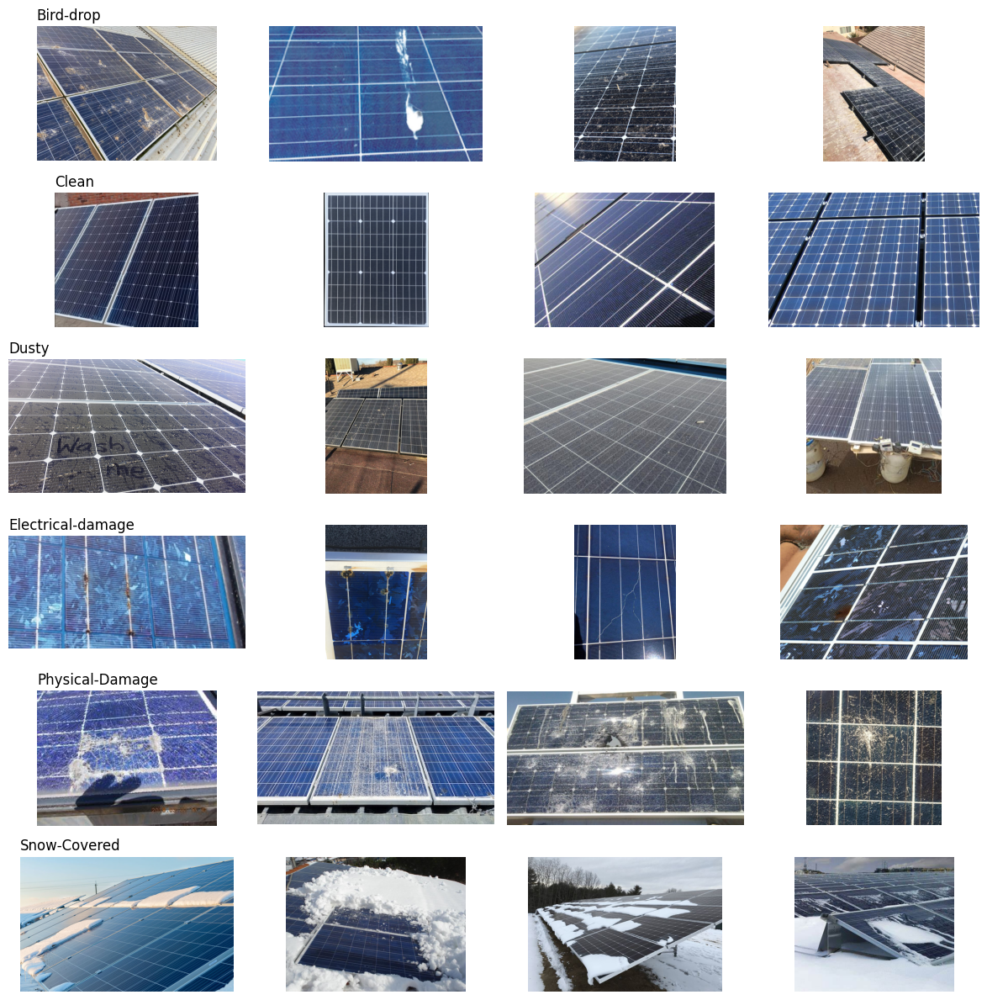

In [133]:
n_per_class = 4
fig, axes = plt.subplots(len(class_names), n_per_class, figsize=(12, 12))
for i, class_name in enumerate(class_names):
  paths = df[df["labels"] == class_name]["image_path"].unique()[:n_per_class]
  for j, path in enumerate(paths):
    with Image.open(path) as img:
      axes[i, j].imshow(img)
      axes[i, j].axis("off")
      if j == 0:
        axes[i, j].set_title(class_name, loc='left')
plt.tight_layout()
plt.show()

# **Preprocessing pipline**

In [134]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

class_names = sorted(df["labels"].unique())
class_to_index = {
    name: index for index, name in enumerate(class_names)
}

def load_image(path, label):
  image = tf.io.read_file(path)
  image = tf.io.decode_image(
       image, channels=3, expand_animations=False
  )
  image.set_shape([None, None, 3])
  image = tf.image.resize(image, IMG_SIZE)
  image = tf.cast(image, tf.float32) / 255.0
  return image, label

def make_dataset(dataframe, training=False):
  paths = dataframe["image_path"].to_numpy()
  labels = dataframe["labels"].map(class_to_index).to_numpy()
  ds = tf.data.Dataset.from_tensor_slices((paths, labels))
  ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

  if training:
    ds = ds.shuffle(500, seed=42)

  return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds_clean = make_dataset(train_df_clean, training=True)
val_ds_clean = make_dataset(val_df_clean)
test_ds_clean = make_dataset(test_df_clean)

print("clean dataset created successfully!")
print("Classes:", class_names)

clean dataset created successfully!
Classes: ['Bird-drop', 'Clean', 'Dusty', 'Electrical-damage', 'Physical-Damage', 'Snow-Covered']


In [135]:
print("Train batches:", len(train_ds_clean))
print("Validation batches:", len(val_ds_clean))
print("Test batches:", len(test_ds_clean))

for images,labels in train_ds_clean.take(1):
  print("Image batch shape:", images.shape)
  print("Label batch shape:", labels.shape)

Train batches: 15
Validation batches: 5
Test batches: 5
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)


In [136]:
print("Train_val:", len(set(train_df_clean["hash"]) & set(val_df_clean["hash"])))
print("Train_Test:", len(set(train_df_clean["hash"]) & set(test_df_clean["hash"])))
print("val_Test:", len(set(val_df_clean["hash"]) & set(test_df_clean["hash"])))

Train_val: 0
Train_Test: 0
val_Test: 0


In [137]:
for name, split in [("train", train_df_clean), ("val", val_df_clean), ("test", test_df_clean)]:
  print(f"n/{name} class counts:")
  print(split["labels"].value_counts())

n/train class counts:
labels
Clean                111
Dusty                109
Bird-drop             84
Snow-Covered          68
Electrical-damage     55
Physical-Damage       38
Name: count, dtype: int64
n/val class counts:
labels
Clean                37
Dusty                36
Bird-drop            28
Snow-Covered         23
Electrical-damage    18
Physical-Damage      13
Name: count, dtype: int64
n/test class counts:
labels
Clean                38
Dusty                37
Bird-drop            29
Snow-Covered         22
Electrical-damage    18
Physical-Damage      12
Name: count, dtype: int64


# **Augmentation**

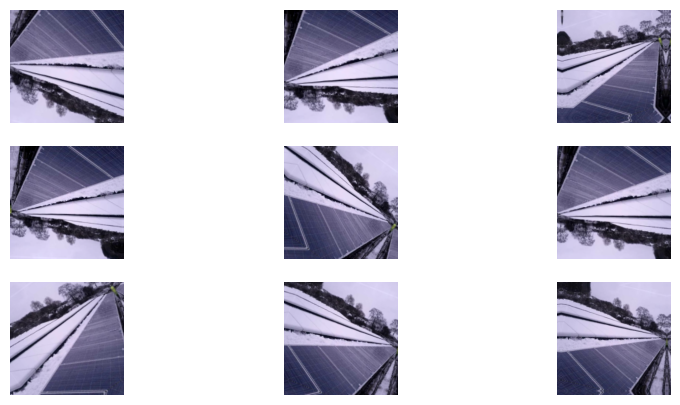

In [138]:
from tensorflow.keras import layers, Sequential

augmentation = Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
], name="augmentation")

img, _ = load_image(train_df['image_path'].iloc[0],0)
plt.figure(figsize=(10, 5))
for i in range(9):
  plt.subplot(3, 3, i+1)
  augmented_img = augmentation(tf.expand_dims(img,0) , training = True)[0]
  plt.imshow(tf.clip_by_value(augmented_img, 0, 1).numpy());
  plt.axis("off")
plt.show()

In [140]:
x,y = next(iter(train_ds_clean))
print("Images:", x.shape , x.dtype)
print("Labels:", y.shape)
print("MIN:", x.numpy().min(), "MAX:",x.numpy().max())

Images: (32, 224, 224, 3) <dtype: 'float32'>
Labels: (32,)
MIN: 0.0 MAX: 1.0


In [141]:
print("Images type:", type(images))
print("Labels type:", type(labels))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

print("Sample labels:", labels[:10].numpy()
      if hasattr(labels[:10], "numpy")
      else labels[:10])

Images type: <class 'tensorflow.python.framework.ops.EagerTensor'>
Labels type: <class 'tensorflow.python.framework.ops.EagerTensor'>
Images shape: (32, 224, 224, 3)
Labels shape: (32,)
Sample labels: [2 3 2 5 0 3 3 2 3 2]


In [142]:
print("Unique labels:", sorted(set(labels.numpy().tolist())))

Unique labels: [0, 1, 2, 3, 5]


## Modeling

In [143]:
import tensorflow as tf
from tensorflow.keras import layers, models

NUM_CLASSES = 6
IMG_SIZE = (224, 224)

cnn_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        256, (3, 3),
        activation="relu",
        padding="same",
        name="last_conv"
    ),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,086 (1.61 MB)

 Trainable params: 422,086 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [144]:
print("train_ds exists:", "train_ds" in globals())
print("val_ds exists:", "val_ds" in globals())

train_ds exists: True
val_ds exists: True


In [145]:
print("Classes:", sorted(train_df_clean["labels"].unique()))

print("\nClass counts:")
print(train_df_clean["labels"].value_counts())

print("\nSample rows:")
print(train_df_clean[["image_path", "labels"]].head())

Classes: ['Bird-drop', 'Clean', 'Dusty', 'Electrical-damage', 'Physical-Damage', 'Snow-Covered']

Class counts:
labels
Clean                111
Dusty                109
Bird-drop             84
Snow-Covered          68
Electrical-damage     55
Physical-Damage       38
Name: count, dtype: int64

Sample rows:
                                            image_path             labels
704  /content/solar_dataset_new/Faulty_solar_panel/...    Physical-Damage
351  /content/solar_dataset_new/Faulty_solar_panel/...              Clean
593  /content/solar_dataset_new/Faulty_solar_panel/...  Electrical-damage
641  /content/solar_dataset_new/Faulty_solar_panel/...  Electrical-damage
290  /content/solar_dataset_new/Faulty_solar_panel/...              Clean


In [146]:

import tensorflow as tf
import numpy as np

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Fixed class-to-index mapping
class_names = sorted(train_df_clean["labels"].unique())

class_to_index = {
    name: index for index, name in enumerate(class_names)
}

print("Class mapping:")
print(class_to_index)

def make_dataset(dataframe, training=False):
    paths = dataframe["image_path"].astype(str).to_numpy()
    labels = dataframe["labels"].map(class_to_index).to_numpy(
        dtype=np.int32
    )

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def load_image(path, label):
        image = tf.io.read_file(path)
        image = tf.io.decode_image(
            image, channels=3, expand_animations=False
        )
        image.set_shape([None, None, 3])

        image = tf.image.resize(image, IMG_SIZE)
        image = tf.cast(image, tf.float32) / 255.0

        return image, label

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        ds = ds.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds

train_ds = make_dataset(train_df_clean, training=True)
val_ds = make_dataset(val_df_clean)
test_ds = make_dataset(test_df_clean)

print("\nDatasets created successfully!")
print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())


Class mapping:
{'Bird-drop': 0, 'Clean': 1, 'Dusty': 2, 'Electrical-damage': 3, 'Physical-Damage': 4, 'Snow-Covered': 5}

Datasets created successfully!
Train batches: 15
Validation batches: 5
Test batches: 5


In [147]:

for images, labels in train_ds.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Image min:", tf.reduce_min(images).numpy())
    print("Image max:", tf.reduce_max(images).numpy())
    print("Sample labels:", labels[:10].numpy())


Images shape: (32, 224, 224, 3)
Labels shape: (32,)
Image min: 0.0
Image max: 1.0
Sample labels: [2 3 2 5 0 3 3 2 3 2]


In [148]:

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_solar_cnn.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks
)


Epoch 1/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 239ms/step - accuracy: 0.2049 - loss: 1.7735
Epoch 1: val_loss improved from None to 1.72546, saving model to best_solar_cnn.keras

Epoch 1: finished saving model to best_solar_cnn.keras
15/15 ━━━━━━━━━━━━━━━━━━━━ 15s 438ms/step - accuracy: 0.2237 - loss: 1.7667 - val_accuracy: 0.3806 - val_loss: 1.7255
Epoch 2/30
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.2445 - loss: 1.7537
Epoch 2: val_loss improved from 1.72546 to 1.64696, saving model to best_solar_cnn.keras

Epoch 2: finished saving model to best_solar_cnn.keras
15/15 ━━━━━━━━━━━━━━━━━━━━ 8s 252ms/step - accuracy: 0.3097 - loss: 1.7069 - val_accuracy: 0.3226 - val_loss: 1.6470
Epoch 3/30
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.3730 - loss: 1.6362
Epoch 3: val_loss improved from 1.64696 to 1.59023, saving model to best_solar_cnn.keras

Epoch 3: finished saving model to best_solar_cnn.keras
15/15 ━━━━━━━━━━━━━━━━━━━━ 8s 253ms/step - accuracy: 0.3806 - loss: 1.6315 - 

5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 415ms/step - accuracy: 0.5705 - loss: 1.1591
Test Loss: 1.1591
Test Accuracy: 0.5705
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 258ms/step
                   precision    recall  f1-score   support

        Bird-drop     0.1667    0.0345    0.0571        29
            Clean     0.6000    0.7105    0.6506        38
            Dusty     0.5000    0.8108    0.6186        37
Electrical-damage     0.6071    0.9444    0.7391        18
  Physical-Damage     0.0000    0.0000    0.0000        12
     Snow-Covered     0.8235    0.6364    0.7179        22

         accuracy                         0.5705       156
        macro avg     0.4496    0.5228    0.4639       156
     weighted avg     0.4819    0.5705    0.5023       156



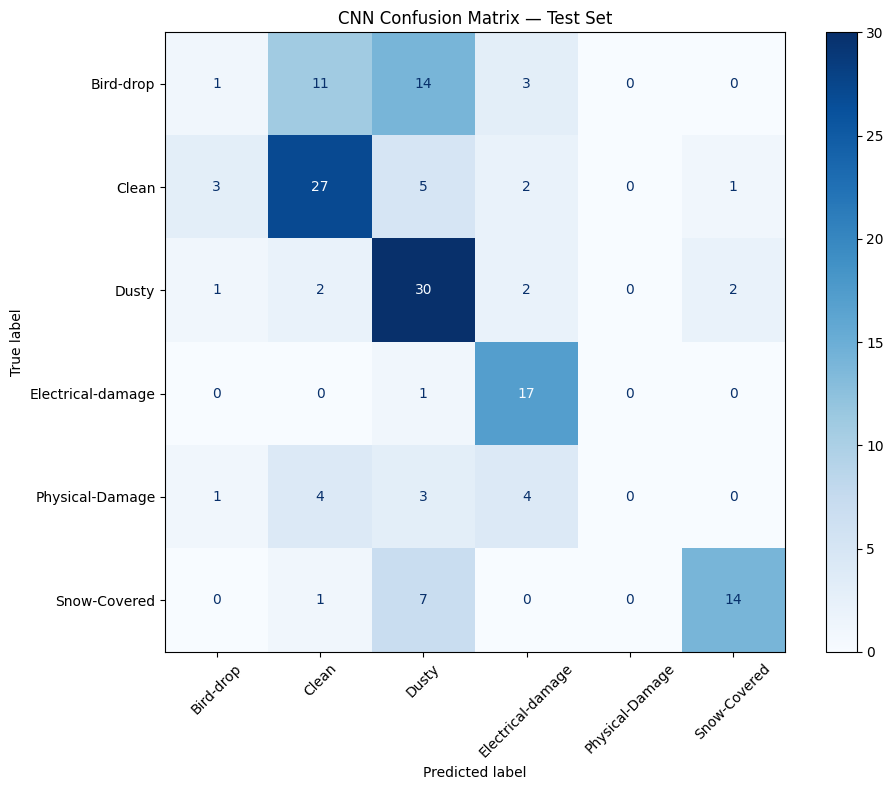

In [149]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Evaluate on unseen test data
test_loss, test_accuracy = cnn_model.evaluate(test_ds, verbose=1)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# Generate predictions
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = cnn_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Classification report
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)
plt.title("CNN Confusion Matrix — Test Set")
plt.tight_layout()
plt.show()


### ploting training history

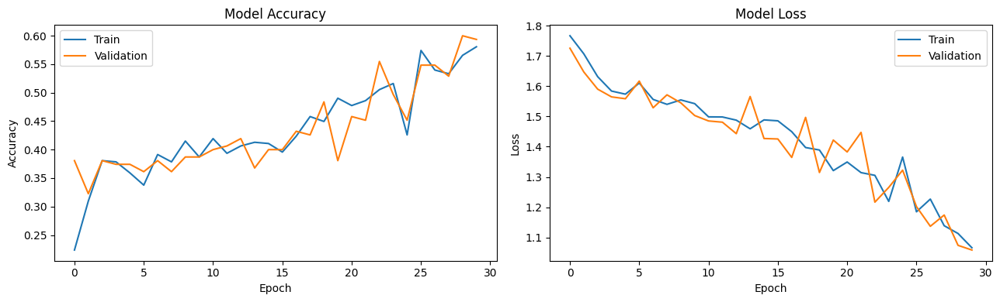

In [150]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history["accuracy"], label="Train")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Train")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()


In [151]:

# Build a functional model that exposes the intermediate layer
grad_input = tf.keras.Input(shape=(224, 224, 3))

x = grad_input
last_conv_output = None

for layer in cnn_model.layers:
    x = layer(x)
    if layer.name == "last_conv":
        last_conv_output = x

grad_model = tf.keras.Model(
    inputs=grad_input,
    outputs=[last_conv_output, x]
)

print("Grad-CAM model ready!")
print("Output shapes:", grad_model.output_shape)


Grad-CAM model ready!
Output shapes: [(None, 28, 28, 256), (None, 6)]


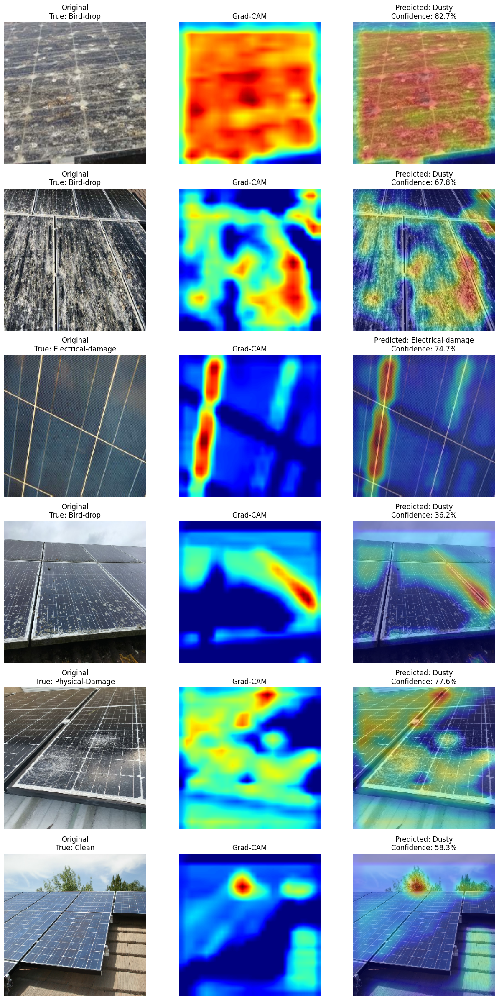

In [152]:

def make_gradcam_heatmap(image, class_index=None):
    image_batch = tf.expand_dims(image, axis=0)

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(
            image_batch, training=False
        )

        if class_index is None:
            class_index = tf.argmax(predictions[0])

        class_score = predictions[:, class_index]

    grads = tape.gradient(class_score, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads, axis=-1
    )
    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + tf.keras.backend.epsilon()
    )

    return heatmap.numpy(), predictions[0].numpy()


# Get images from the existing test dataset
test_images, test_labels = next(iter(test_ds))

num_images = min(6, len(test_images))
fig, axes = plt.subplots(
    num_images, 3, figsize=(13, 4 * num_images)
)

if num_images == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(num_images):
    image = test_images[i].numpy()
    true_idx = int(test_labels[i].numpy())

    heatmap, probs = make_gradcam_heatmap(image)
    pred_idx = int(np.argmax(probs))

    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis], (224, 224)
    ).numpy().squeeze()

    colored_heatmap = plt.get_cmap("jet")(
        heatmap_resized
    )[..., :3]

    overlay = np.clip(
        0.6 * image + 0.4 * colored_heatmap, 0, 1
    )

    axes[i, 0].imshow(image)
    axes[i, 0].set_title(
        f"Original\nTrue: {class_names[true_idx]}"
    )

    axes[i, 1].imshow(heatmap_resized, cmap="jet")
    axes[i, 1].set_title("Grad-CAM")

    axes[i, 2].imshow(overlay)
    axes[i, 2].set_title(
        f"Predicted: {class_names[pred_idx]}\n"
        f"Confidence: {probs[pred_idx]:.1%}"
    )

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


Total wrong predictions: 67
Total test images: 156


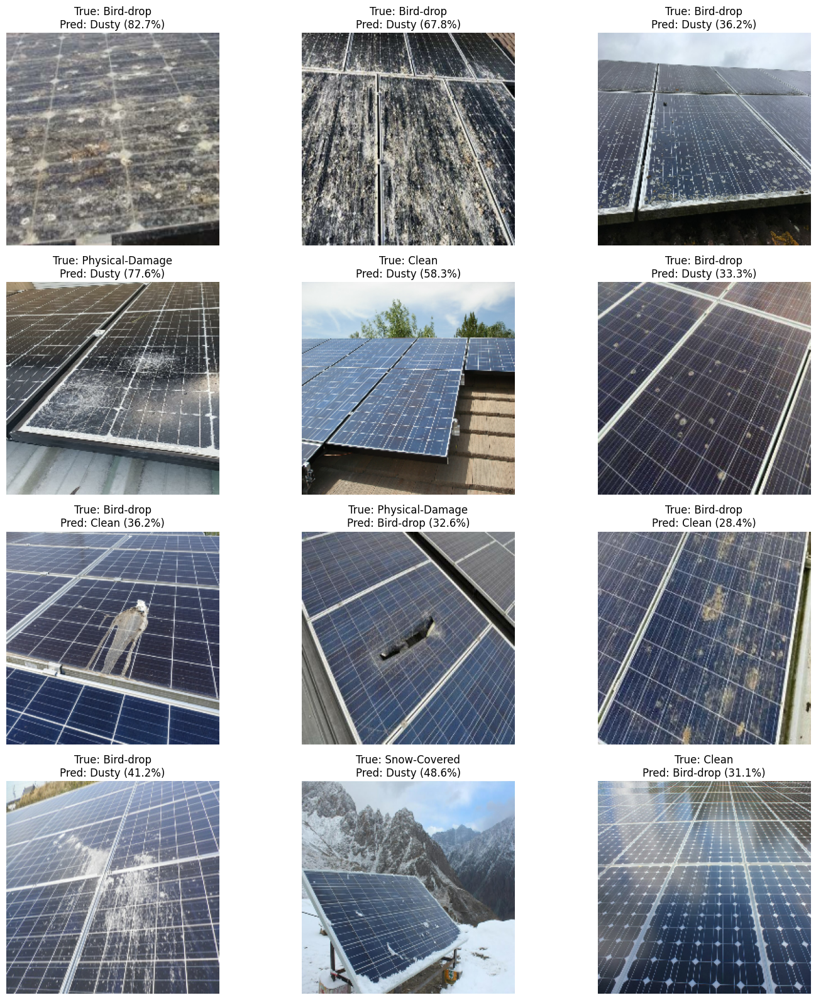

In [153]:

import matplotlib.pyplot as plt
import numpy as np

wrong_indices = np.where(y_true != y_pred)[0]

print("Total wrong predictions:", len(wrong_indices))
print("Total test images:", len(y_true))

num_show = min(12, len(wrong_indices))
fig, axes = plt.subplots(
    (num_show + 2) // 3, 3,
    figsize=(15, 4 * ((num_show + 2) // 3))
)
axes = np.array(axes).reshape(-1)

for ax, idx in zip(axes, wrong_indices[:num_show]):
    image, label = test_ds.unbatch().skip(int(idx)).take(1).get_single_element()
    probs = y_prob[idx]
    pred_idx = int(np.argmax(probs))

    ax.imshow(image.numpy())
    ax.set_title(
        f"True: {class_names[int(label.numpy())]}\n"
        f"Pred: {class_names[pred_idx]} "
        f"({probs[pred_idx]:.1%})"
    )
    ax.axis("off")

for ax in axes[num_show:]:
    ax.axis("off")

plt.tight_layout()
plt.show()


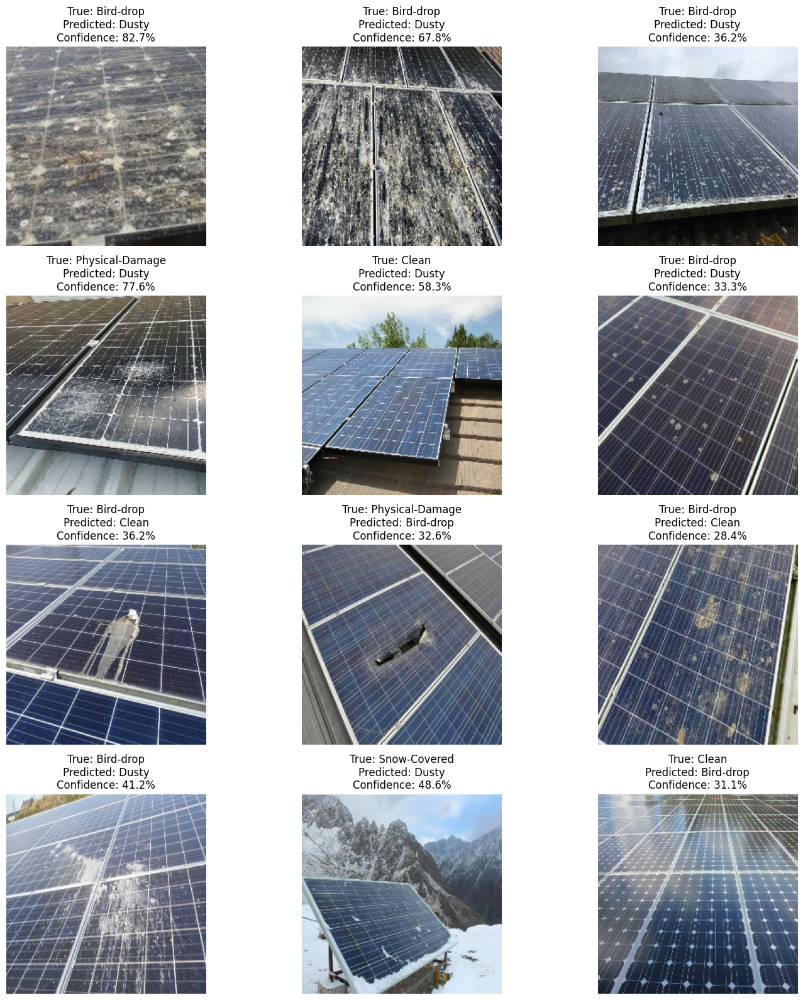

In [155]:

import matplotlib.pyplot as plt
import numpy as np

wrong_indices = np.where(y_true != y_pred)[0]
num_show = min(12, len(wrong_indices))

fig, axes = plt.subplots(4, 3, figsize=(15, 16))
axes = axes.flatten()

for ax, idx in zip(axes, wrong_indices[:num_show]):
    image = test_images[idx].numpy()
    true_idx = int(y_true[idx])
    pred_idx = int(y_pred[idx])
    confidence = float(y_prob[idx, pred_idx])

    ax.imshow(image)
    ax.set_title(
        f"True: {class_names[true_idx]}\n"
        f"Predicted: {class_names[pred_idx]}\n"
        f"Confidence: {confidence:.1%}"
    )
    ax.axis("off")

for ax in axes[num_show:]:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [156]:

import tensorflow as tf
from tensorflow.keras import layers, Model

# Pretrained feature extractor
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

# Light augmentation during training only
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.05)(x)
x = layers.RandomZoom(0.1)(x)

# MobileNetV2 preprocessing: [0, 1] -> [-1, 1]
x = layers.Rescaling(scale=2.0, offset=-1.0)(x)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(6, activation="softmax")(x)

transfer_model = Model(inputs, outputs)

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

transfer_model.summary()


Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_3 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_3               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_3 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [157]:

from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import tensorflow as tf

# Calculate class weights from training data only
class_ids = np.arange(len(class_names))
train_labels = train_df_clean["labels"].map(class_to_index).to_numpy()

weights = compute_class_weight(
    class_weight="balanced",
    classes=class_ids,
    y=train_labels
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(class_ids, weights)
}

print("Class weights:")
for class_id, weight in class_weights.items():
    print(f"{class_names[class_id]}: {weight:.3f}")

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_mobilenetv2.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history_transfer = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights,
    callbacks=callbacks
)


Class weights:
Bird-drop: 0.923
Clean: 0.698
Dusty: 0.711
Electrical-damage: 1.409
Physical-Damage: 2.039
Snow-Covered: 1.140
Epoch 1/15
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.2000 - loss: 2.0862
Epoch 1: val_loss improved from None to 1.47513, saving model to best_mobilenetv2.keras

Epoch 1: finished saving model to best_mobilenetv2.keras
15/15 ━━━━━━━━━━━━━━━━━━━━ 15s 387ms/step - accuracy: 0.2495 - loss: 1.9473 - val_accuracy: 0.4516 - val_loss: 1.4751 - learning_rate: 0.0010
Epoch 2/15
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.3794 - loss: 1.5959
Epoch 2: val_loss improved from 1.47513 to 1.16984, saving model to best_mobilenetv2.keras

Epoch 2: finished saving model to best_mobilenetv2.keras
15/15 ━━━━━━━━━━━━━━━━━━━━ 8s 287ms/step - accuracy: 0.4151 - loss: 1.4965 - val_accuracy: 0.5871 - val_loss: 1.1698 - learning_rate: 0.0010
Epoch 3/15
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.5382 - loss: 1.2054
Epoch 3: val_loss improved from 1.16984 t

In [158]:

from sklearn.metrics import classification_report
import numpy as np

test_loss, test_accuracy = transfer_model.evaluate(
    test_ds, verbose=1
)

y_true_transfer = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob_transfer = transfer_model.predict(test_ds, verbose=1)
y_pred_transfer = np.argmax(y_prob_transfer, axis=1)

print(f"MobileNetV2 Test Accuracy: {test_accuracy:.4f}")
print(f"MobileNetV2 Test Loss: {test_loss:.4f}")

print(classification_report(
    y_true_transfer,
    y_pred_transfer,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))


5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 307ms/step - accuracy: 0.7564 - loss: 0.7172
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 320ms/step
MobileNetV2 Test Accuracy: 0.7564
MobileNetV2 Test Loss: 0.7172
                   precision    recall  f1-score   support

        Bird-drop     0.6000    0.5172    0.5556        29
            Clean     0.7059    0.9474    0.8090        38
            Dusty     0.8000    0.6486    0.7164        37
Electrical-damage     0.8095    0.9444    0.8718        18
  Physical-Damage     0.8182    0.7500    0.7826        12
     Snow-Covered     0.9444    0.7727    0.8500        22

         accuracy                         0.7564       156
        macro avg     0.7797    0.7634    0.7642       156
     weighted avg     0.7628    0.7564    0.7509       156



In [159]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_mobilenetv2.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [160]:

# Unfreeze the base model
base_model.trainable = True

# Freeze most layers and fine-tune only the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for more stable fine-tuning
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a much smaller learning rate
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_finetune = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=callbacks
)


Epoch 1/10
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.8265 - loss: 0.4664
Epoch 1: val_loss improved from 0.75216 to 0.74834, saving model to best_mobilenetv2.keras

Epoch 1: finished saving model to best_mobilenetv2.keras
15/15 ━━━━━━━━━━━━━━━━━━━━ 14s 321ms/step - accuracy: 0.8409 - loss: 0.4701 - val_accuracy: 0.7484 - val_loss: 0.7483 - learning_rate: 1.0000e-05
Epoch 2/10
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.8170 - loss: 0.5427
Epoch 2: val_loss improved from 0.74834 to 0.72427, saving model to best_mobilenetv2.keras

Epoch 2: finished saving model to best_mobilenetv2.keras
15/15 ━━━━━━━━━━━━━━━━━━━━ 8s 226ms/step - accuracy: 0.8323 - loss: 0.4880 - val_accuracy: 0.7419 - val_loss: 0.7243 - learning_rate: 1.0000e-05
Epoch 3/10
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.7957 - loss: 0.4332
Epoch 3: val_loss did not improve from 0.72427
15/15 ━━━━━━━━━━━━━━━━━━━━ 8s 251ms/step - accuracy: 0.8301 - loss: 0.4123 - val_accuracy: 0.7613 - val_loss:

In [161]:

from sklearn.metrics import classification_report
import numpy as np

test_loss, test_accuracy = transfer_model.evaluate(
    test_ds, verbose=1
)

y_true_transfer = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob_transfer = transfer_model.predict(test_ds, verbose=1)
y_pred_transfer = np.argmax(y_prob_transfer, axis=1)

print(f"MobileNetV2 Test Accuracy: {test_accuracy:.4f}")
print(f"MobileNetV2 Test Loss: {test_loss:.4f}")

print(classification_report(
    y_true_transfer,
    y_pred_transfer,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))


5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 304ms/step - accuracy: 0.7756 - loss: 0.6467
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 328ms/step
MobileNetV2 Test Accuracy: 0.7756
MobileNetV2 Test Loss: 0.6467
                   precision    recall  f1-score   support

        Bird-drop     0.7000    0.4828    0.5714        29
            Clean     0.7347    0.9474    0.8276        38
            Dusty     0.7179    0.7568    0.7368        37
Electrical-damage     0.8095    0.9444    0.8718        18
  Physical-Damage     0.9000    0.7500    0.8182        12
     Snow-Covered     1.0000    0.7727    0.8718        22

         accuracy                         0.7756       156
        macro avg     0.8104    0.7757    0.7829       156
     weighted avg     0.7830    0.7756    0.7691       156



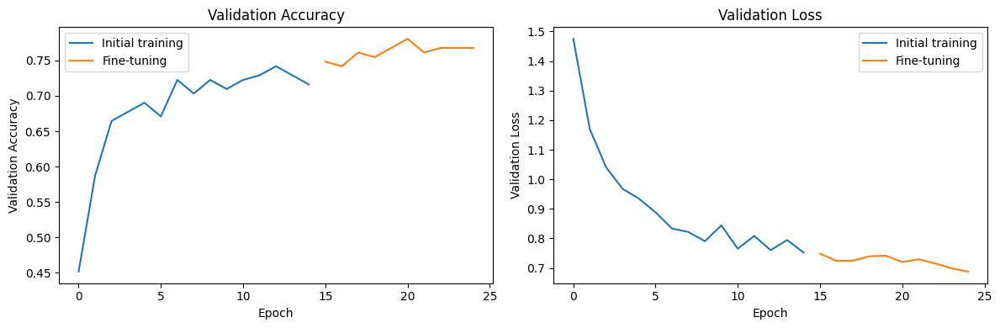

In [162]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_transfer.history["val_accuracy"], label="Initial training")
plt.plot(
    range(
        len(history_transfer.history["val_accuracy"]),
        len(history_transfer.history["val_accuracy"])
        + len(history_finetune.history["val_accuracy"])
    ),
    history_finetune.history["val_accuracy"],
    label="Fine-tuning"
)
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_transfer.history["val_loss"], label="Initial training")
plt.plot(
    range(
        len(history_transfer.history["val_loss"]),
        len(history_transfer.history["val_loss"])
        + len(history_finetune.history["val_loss"])
    ),
    history_finetune.history["val_loss"],
    label="Fine-tuning"
)
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()


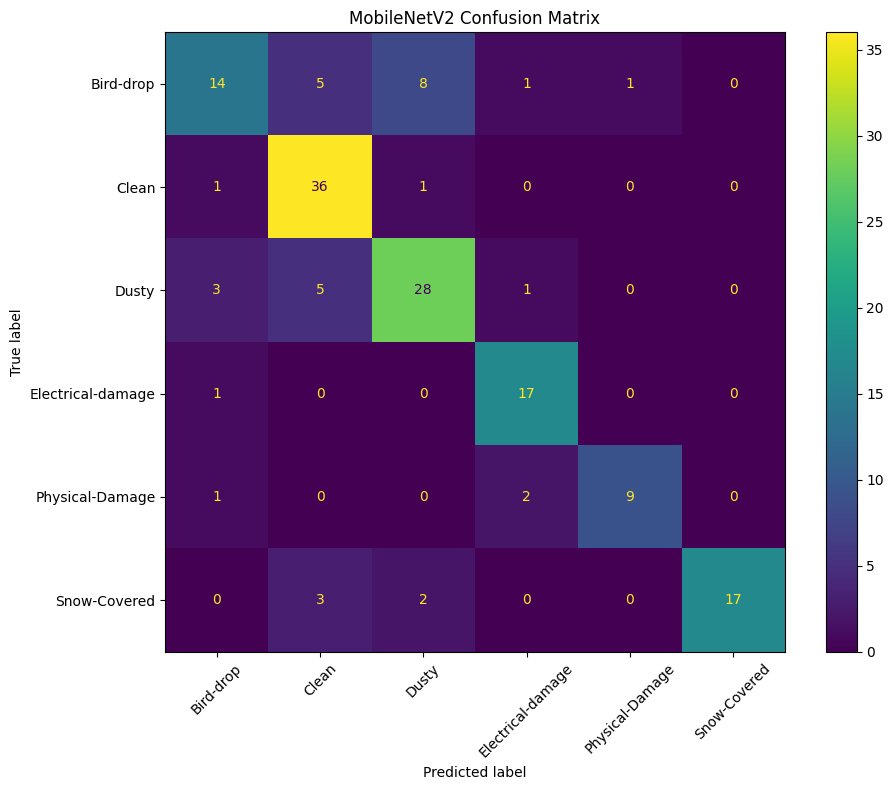

In [163]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = transfer_model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

cm = confusion_matrix(
    y_true, y_pred,
    labels=np.arange(len(class_names))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, xticks_rotation=45, values_format="d")
plt.title("MobileNetV2 Confusion Matrix")
plt.tight_layout()
plt.show()


In [164]:

# Keep only the last 20 layers trainable
base_model.trainable = True

for layer in base_model.layers[:-20]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a smaller learning rate
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-6),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=1,
        min_lr=1e-7,
        verbose=1
    )
]

history_finetune2 = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    class_weight=class_weights,
    callbacks=fine_tune_callbacks
)


Epoch 1/8
15/15 ━━━━━━━━━━━━━━━━━━━━ 15s 352ms/step - accuracy: 0.8667 - loss: 0.3437 - val_accuracy: 0.7613 - val_loss: 0.6907 - learning_rate: 1.0000e-06
Epoch 2/8
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9017 - loss: 0.2807
Epoch 2: ReduceLROnPlateau reducing learning rate to 1.9999999949504855e-07.
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 180ms/step - accuracy: 0.8925 - loss: 0.3147 - val_accuracy: 0.7613 - val_loss: 0.6989 - learning_rate: 1.0000e-06
Epoch 3/8
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.8742 - loss: 0.3445
Epoch 3: ReduceLROnPlateau reducing learning rate to 1e-07.
15/15 ━━━━━━━━━━━━━━━━━━━━ 8s 250ms/step - accuracy: 0.8753 - loss: 0.3427 - val_accuracy: 0.7613 - val_loss: 0.7005 - learning_rate: 2.0000e-07
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.


In [165]:

print("Model exists:", "transfer_model" in globals())
print("Training dataset exists:", "train_ds" in globals())
print("Validation dataset exists:", "val_ds" in globals())
print("Class weights exist:", "class_weights" in globals())
print("Initial history exists:", "history_transfer" in globals())


Model exists: True
Training dataset exists: True
Validation dataset exists: True
Class weights exist: True
Initial history exists: True


In [166]:

# Save the current model so we don't lose it
transfer_model.save("/content/mobilenetv2_current.keras")

print("Current model saved successfully!")


Current model saved successfully!


In [167]:

import numpy as np

print("Initial training — best validation accuracy:",
      round(max(history_transfer.history["val_accuracy"]), 4))

print("Initial training — lowest validation loss:",
      round(min(history_transfer.history["val_loss"]), 4))

print("Fine-tuning — best validation accuracy:",
      round(max(history_finetune.history["val_accuracy"]), 4))

print("Fine-tuning — lowest validation loss:",
      round(min(history_finetune.history["val_loss"]), 4))


Initial training — best validation accuracy: 0.7419
Initial training — lowest validation loss: 0.7522
Fine-tuning — best validation accuracy: 0.7806
Fine-tuning — lowest validation loss: 0.6879


In [169]:
print("Model summary:")
transfer_model.summary()

print("\nBase model:")
for layer in transfer_model.layers:
    print(layer.name, type(layer).name, layer.trainable)

Model summary:


Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_3 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_3               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_3 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,670,804 (17.82 MB)

 Trainable params: 1,202,566 (4.59 MB)

 Non-trainable params: 1,063,104 (4.06 MB)

 Optimizer params: 2,405,134 (9.17 MB)


Base model:
input_layer_9 InputLayer True
random_flip_3 RandomFlip True
random_rotation_3 RandomRotation True
random_zoom_3 RandomZoom True
rescaling_1 Rescaling True
mobilenetv2_1.00_224 Functional True
global_average_pooling2d_3 GlobalAveragePooling2D True
dropout_5 Dropout True
dense_5 Dense True


In [170]:
import tensorflow as tf

# Keep the existing model and weights
base_model = transfer_model.get_layer("mobilenetv2_1.00_224")

# Unfreeze only the last 30 layers
base_model.trainable = True

fine_tune_at = len(base_model.layers) - 30

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for stable fine-tuning
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a low learning rate
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=["accuracy"]
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_mobilenetv2_finetuned.keras",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        min_delta=0.001,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history_fine = transfer_model.fit(
    train_ds_clean,
    validation_data=val_ds_clean,
    epochs=20,
    callbacks=callbacks,
    class_weight=class_weights
)

print(
    f"Best validation accuracy: "
    f"{max(history_fine.history['val_accuracy']) * 100:.2f}%"
)

Epoch 1/20
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.8974 - loss: 0.3346
Epoch 1: val_accuracy improved from None to 0.76129, saving model to /content/best_mobilenetv2_finetuned.keras

Epoch 1: finished saving model to /content/best_mobilenetv2_finetuned.keras
15/15 ━━━━━━━━━━━━━━━━━━━━ 22s 397ms/step - accuracy: 0.8710 - loss: 0.3620 - val_accuracy: 0.7613 - val_loss: 0.7470 - learning_rate: 1.0000e-05
Epoch 2/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.8609 - loss: 0.3441
Epoch 2: val_accuracy did not improve from 0.76129
15/15 ━━━━━━━━━━━━━━━━━━━━ 9s 259ms/step - accuracy: 0.8753 - loss: 0.3374 - val_accuracy: 0.7613 - val_loss: 0.6783 - learning_rate: 1.0000e-05
Epoch 3/20
14/15 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.8478 - loss: 0.3743
Epoch 3: val_accuracy did not improve from 0.76129
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 258ms/step - accuracy: 0.8624 - loss: 0.3515 - val_accuracy: 0.7484 - val_loss: 0.7355 - learning_rate: 1.0000e-05
Epoch 4/20
15/15 ━

In [171]:
print(
    f"Best Validation Accuracy: "
    f"{max(history_fine.history['val_accuracy']) * 100:.2f}%"
)

Best Validation Accuracy: 77.42%


In [172]:
!pip -q install scikit-image

In [173]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

required_vars = [
    "train_df_clean",
    "val_df_clean",
    "test_df_clean"
]

for var in required_vars:
    print(var, "exists:", var in globals())

print("\nTrain:", len(train_df_clean))
print("Validation:", len(val_df_clean))
print("Test:", len(test_df_clean))

print("\nClasses:")
print(sorted(train_df_clean["labels"].unique()))

print("\nTrain class distribution:")
print(train_df_clean["labels"].value_counts())

train_df_clean exists: True
val_df_clean exists: True
test_df_clean exists: True

Train: 465
Validation: 155
Test: 156

Classes:
['Bird-drop', 'Clean', 'Dusty', 'Electrical-damage', 'Physical-Damage', 'Snow-Covered']

Train class distribution:
labels
Clean                111
Dusty                109
Bird-drop             84
Snow-Covered          68
Electrical-damage     55
Physical-Damage       38
Name: count, dtype: int64


**hog feature extract**





In [174]:
from PIL import Image
from skimage.feature import hog
from tqdm.auto import tqdm

IMG_SIZE_HOG = (96, 96)

def extract_hog_features(dataframe):
    features = []
    labels = []

    for _, row in tqdm(
        dataframe.iterrows(),
        total=len(dataframe),
        desc="Extracting HOG"
    ):
        image_path = row["image_path"]

        with Image.open(image_path) as img:
            img = img.convert("RGB")
            img = img.resize(IMG_SIZE_HOG)

            image = np.array(img)

        # Convert RGB image to grayscale
        gray = np.dot(
            image[..., :3],
            [0.299, 0.587, 0.114]
        ).astype(np.uint8)

        feature_vector = hog(
            gray,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys"
        )

        features.append(feature_vector)
        labels.append(row["labels"])

    return np.asarray(features, dtype=np.float32), np.asarray(labels)


print("HOG feature extraction function is ready.")

HOG feature extraction function is ready.


In [175]:
X_train_hog, y_train_hog = extract_hog_features(train_df_clean)

X_val_hog, y_val_hog = extract_hog_features(val_df_clean)

X_test_hog, y_test_hog = extract_hog_features(test_df_clean)

print("Train features:", X_train_hog.shape)
print("Validation features:", X_val_hog.shape)
print("Test features:", X_test_hog.shape)

print("\nNumber of classes:", len(np.unique(y_train_hog)))
print("Train labels:", np.unique(y_train_hog))

Extracting HOG:   0%|          | 0/465 [00:00<?, ?it/s]

Extracting HOG:   0%|          | 0/155 [00:00<?, ?it/s]

Extracting HOG:   0%|          | 0/156 [00:00<?, ?it/s]

Train features: (465, 4356)
Validation features: (155, 4356)
Test features: (156, 4356)

Number of classes: 6
Train labels: ['Bird-drop' 'Clean' 'Dusty' 'Electrical-damage' 'Physical-Damage'
 'Snow-Covered']


**models**


In [176]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

models = {
    "SVM (RBF)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            C=10,
            gamma="scale",
            probability=True,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(
            n_neighbors=5,
            weights="distance"
        ))
    ]),

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ])
}

print("Models ready:")
for name in models:
    print("-", name)

Models ready:
- SVM (RBF)
- Random Forest
- KNN
- Logistic Regression


In [177]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import time

results = []
trained_models = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    start_time = time.time()

    model.fit(X_train_hog, y_train_hog)

    training_time = time.time() - start_time

    val_pred = model.predict(X_val_hog)

    accuracy = accuracy_score(y_val_hog, val_pred)

    precision = precision_score(
        y_val_hog,
        val_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_val_hog,
        val_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_val_hog,
        val_pred,
        average="macro",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
        "Training Time (sec)": training_time
    })

    trained_models[name] = model

    print(f"Validation Accuracy: {accuracy:.4f}")
    print(f"Validation Macro F1: {f1:.4f}")
    print(f"Training Time: {training_time:.2f} sec")

print("\nAll models trained.")


Training SVM (RBF)...
Validation Accuracy: 0.5419
Validation Macro F1: 0.5553
Training Time: 3.81 sec

Training Random Forest...
Validation Accuracy: 0.4581
Validation Macro F1: 0.4896
Training Time: 3.63 sec

Training KNN...
Validation Accuracy: 0.4452
Validation Macro F1: 0.4808
Training Time: 0.02 sec

Training Logistic Regression...
Validation Accuracy: 0.4903
Validation Macro F1: 0.5135
Training Time: 1.27 sec

All models trained.


In [178]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Training Time (sec)": "{:.2f}"
    })
)

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model based on Validation Macro F1:", best_model_name)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Training Time (sec)
0,SVM (RBF),0.5419,0.6321,0.5335,0.5553,3.81
1,Logistic Regression,0.4903,0.5265,0.5121,0.5135,1.27
2,Random Forest,0.4581,0.6159,0.4584,0.4896,3.63
3,KNN,0.4452,0.6175,0.4692,0.4808,0.02


Best model based on Validation Macro F1: SVM (RBF)


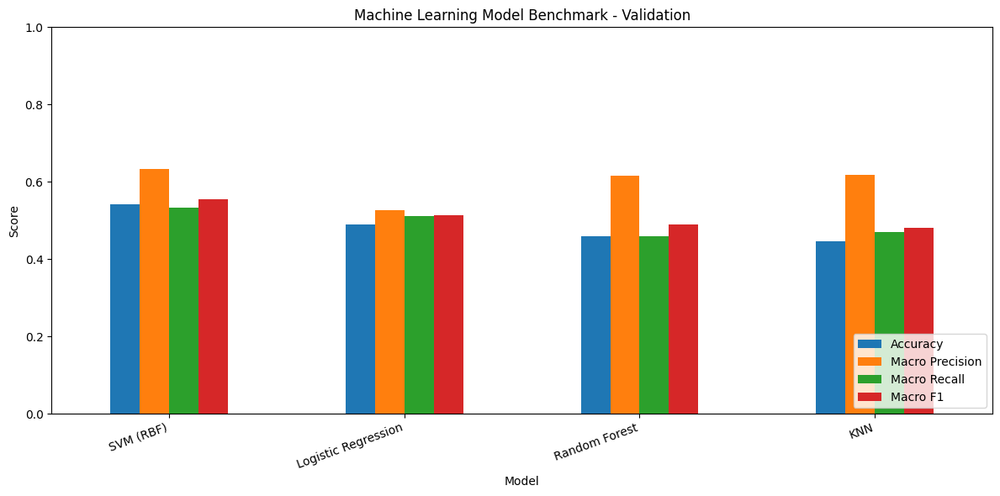

In [179]:
metrics_to_plot = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

results_df.set_index("Model")[metrics_to_plot].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Benchmark - Validation")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [180]:
from sklearn.metrics import classification_report

test_pred = best_model.predict(X_test_hog)

print("Selected model:", best_model_name)

print("\nFinal Test Classification Report:\n")

print(classification_report(
    y_test_hog,
    test_pred,
    labels=sorted(np.unique(y_train_hog)),
    digits=4,
    zero_division=0
))

Selected model: SVM (RBF)

Final Test Classification Report:

                   precision    recall  f1-score   support

        Bird-drop     0.5667    0.5862    0.5763        29
            Clean     0.4694    0.6053    0.5287        38
            Dusty     0.3556    0.4324    0.3902        37
Electrical-damage     0.6875    0.6111    0.6471        18
  Physical-Damage     0.5000    0.1667    0.2500        12
     Snow-Covered     0.6667    0.3636    0.4706        22

         accuracy                         0.4936       156
        macro avg     0.5410    0.4609    0.4771       156
     weighted avg     0.5158    0.4936    0.4887       156



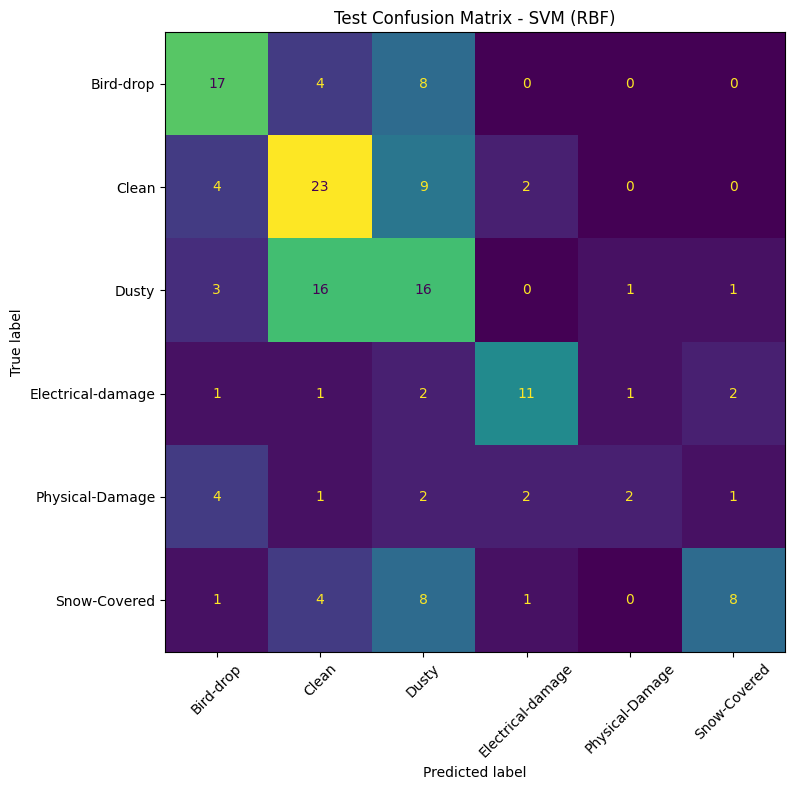

In [181]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

labels_order = sorted(np.unique(y_train_hog))

cm = confusion_matrix(
    y_test_hog,
    test_pred,
    labels=labels_order
)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels_order
)

disp.plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

plt.title(f"Test Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

In [182]:
# Get prediction probabilities for the test images
test_probabilities = best_model.predict_proba(X_test_hog)

# Predicted class index for each image
predicted_indices = np.argmax(test_probabilities, axis=1)

# Highest probability for each image
confidence_scores = np.max(test_probabilities, axis=1)

# Difference between the two highest probabilities
sorted_probabilities = np.sort(test_probabilities, axis=1)

confidence_margins = (
    sorted_probabilities[:, -1]
    - sorted_probabilities[:, -2]
)

# Map predicted indices to class names
model_classes = best_model.classes_

predicted_labels = model_classes[predicted_indices]

# Intelligent Review thresholds
CONFIDENCE_THRESHOLD = 0.60
MARGIN_THRESHOLD = 0.15

needs_review = (
    (confidence_scores < CONFIDENCE_THRESHOLD)
    | (confidence_margins < MARGIN_THRESHOLD)
)

# Create review table
review_df = test_df_clean.reset_index(drop=True).copy()

review_df["Predicted Label"] = predicted_labels
review_df["Confidence"] = confidence_scores
review_df["Top Two Margin"] = confidence_margins
review_df["Needs Review"] = needs_review

review_df["Review Reason"] = np.where(
    confidence_scores < CONFIDENCE_THRESHOLD,
    "Low prediction confidence",
    np.where(
        confidence_margins < MARGIN_THRESHOLD,
        "Competing class predictions",
        "No review flag"
    )
)

review_queue = review_df[
    review_df["Needs Review"]
].copy()

review_queue = review_queue.sort_values(
    by="Confidence",
    ascending=True
)

print("Total test images:", len(review_df))
print("Images flagged for review:", len(review_queue))
print(
    "Review rate:",
    f"{len(review_queue) / max(len(review_df), 1):.2%}"
)

display(
    review_queue[
        [
            "image_path",
            "labels",
            "Predicted Label",
            "Confidence",
            "Top Two Margin",
            "Review Reason"
        ]
    ].head(20)
)

Total test images: 156
Images flagged for review: 129
Review rate: 82.69%


,image_path,labels,Predicted Label,Confidence,Top Two Margin,Review Reason
144,/content/solar_dataset_new/Faulty_solar_panel/...,Bird-drop,Dusty,0.186544,0.000682,Low prediction confidence
146,/content/solar_dataset_new/Faulty_solar_panel/...,Clean,Electrical-damage,0.216765,0.003182,Low prediction confidence
143,/content/solar_dataset_new/Faulty_solar_panel/...,Bird-drop,Dusty,0.223194,0.008221,Low prediction confidence
2,/content/solar_dataset_new/Faulty_solar_panel/...,Electrical-damage,Electrical-damage,0.234476,0.013190,Low prediction confidence
127,/content/solar_dataset_new/Faulty_solar_panel/...,Snow-Covered,Dusty,0.235839,0.036130,Low prediction confidence
138,/content/solar_dataset_new/Faulty_solar_panel/...,Dusty,Clean,0.248546,0.006929,Low prediction confidence
46,/content/solar_dataset_new/Faulty_solar_panel/...,Electrical-damage,Dusty,0.251555,0.044761,Low prediction confidence
111,/content/solar_dataset_new/Faulty_solar_panel/...,Electrical-damage,Dusty,0.253098,0.068626,Low prediction confidence
42,/content/solar_dataset_new/Faulty_solar_panel/...,Clean,Snow-Covered,0.253232,0.018134,Low prediction confidence
76,/content/solar_dataset_new/Faulty_solar_panel/...,Clean,Clean,0.261925,0.002073,Low prediction confidence


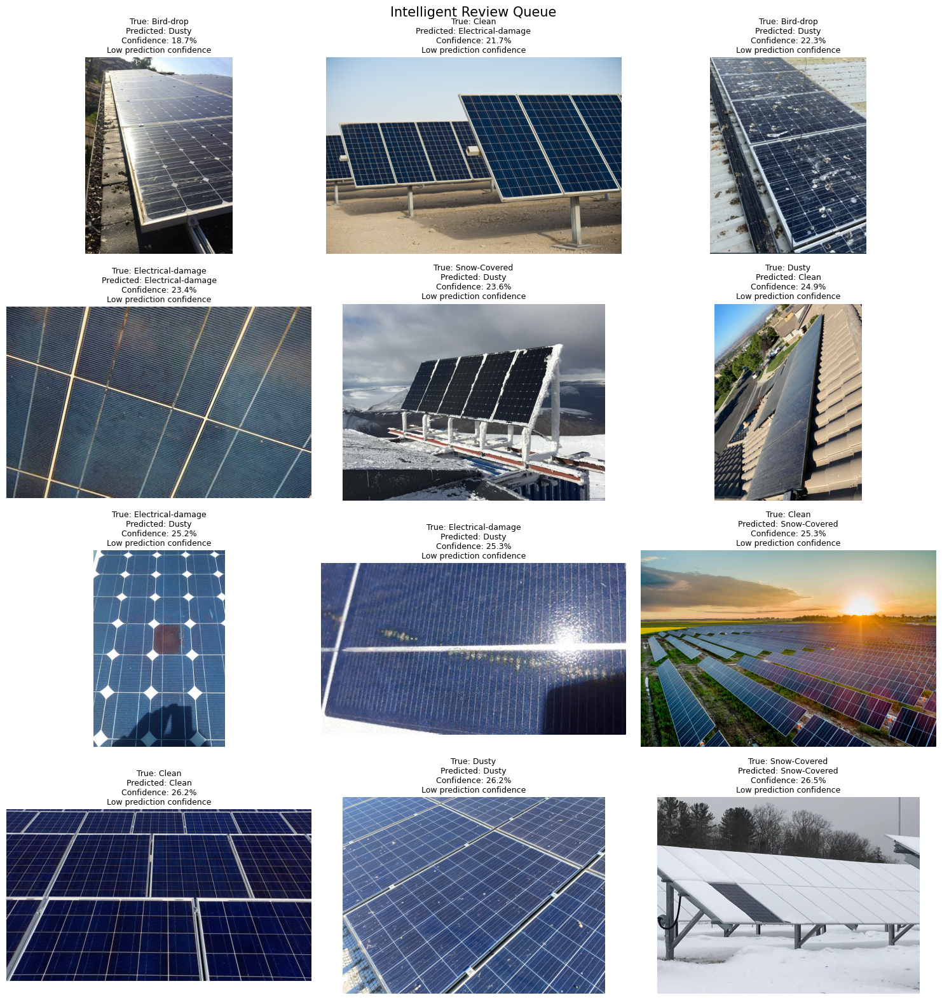

In [183]:
from PIL import Image

NUM_IMAGES_TO_SHOW = min(12, len(review_queue))

if NUM_IMAGES_TO_SHOW == 0:
    print("No images were flagged for review.")
else:
    rows = (NUM_IMAGES_TO_SHOW + 2) // 3

    fig, axes = plt.subplots(
        rows, 3,
        figsize=(15, 4 * rows)
    )

    axes = np.array(axes).reshape(-1)

    for ax, (_, row) in zip(
        axes,
        review_queue.head(NUM_IMAGES_TO_SHOW).iterrows()
    ):
        with Image.open(row["image_path"]) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f"True: {row['labels']}\n"
            f"Predicted: {row['Predicted Label']}\n"
            f"Confidence: {row['Confidence']:.1%}\n"
            f"{row['Review Reason']}",
            fontsize=9
        )

        ax.axis("off")

    for ax in axes[NUM_IMAGES_TO_SHOW:]:
        ax.axis("off")

    plt.suptitle(
        "Intelligent Review Queue",
        fontsize=15
    )
    plt.tight_layout()
    plt.show()

In [184]:
# Save benchmark results
results_df.to_csv(
    "/content/ml_benchmark_results.csv",
    index=False
)

# Save all test predictions and review flags
review_df.to_csv(
    "/content/intelligent_review_results.csv",
    index=False
)

# Save only the images flagged for review
review_queue.to_csv(
    "/content/intelligent_review_queue.csv",
    index=False
)

print("Files saved successfully:")
print("1. ml_benchmark_results.csv")
print("2. intelligent_review_results.csv")
print("3. intelligent_review_queue.csv")

Files saved successfully:
1. ml_benchmark_results.csv
2. intelligent_review_results.csv
3. intelligent_review_queue.csv


In [185]:
from google.colab import files

files.download("/content/ml_benchmark_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [186]:
files.download("/content/intelligent_review_queue.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [187]:
import joblib
import os

# Save the selected model
joblib.dump(
    best_model,
    "/content/solar_svm_model.joblib"
)

print("Selected model:", best_model_name)
print("Model saved successfully!")

Selected model: SVM (RBF)
Model saved successfully!


In [188]:
from google.colab import files

files.download("/content/solar_svm_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>